In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df_org = pd.read_csv("./house_train.csv")
df = df_org.copy()
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print(df.shape)
print(df.dtypes.value_counts())
isnull_series = df.isnull().sum()
print(isnull_series[isnull_series > 0].sort_values(ascending = False))

(1460, 81)
object     43
int64      35
float64     3
dtype: int64
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64


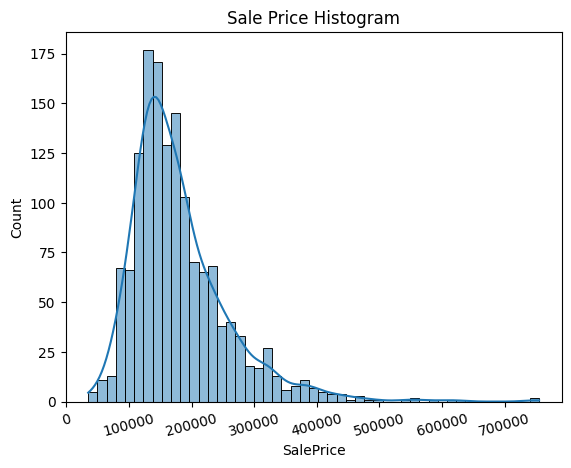

In [4]:
plt.title("Sale Price Histogram")
plt.xticks(rotation = 15)
sns.histplot(df["SalePrice"], kde = True)
plt.show()

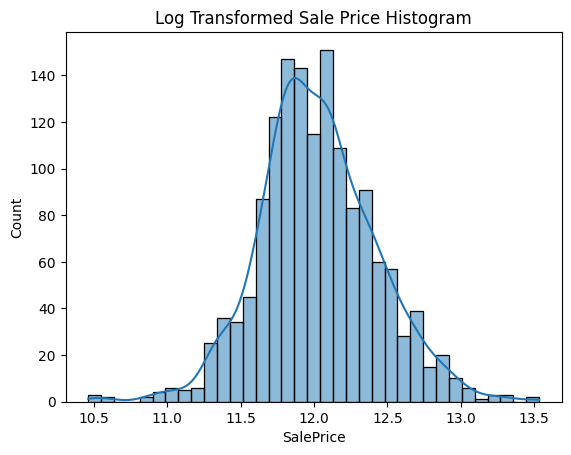

In [5]:
plt.title("Log Transformed Sale Price Histogram")
log_SalePrice = np.log1p(df["SalePrice"])
sns.histplot(log_SalePrice, kde = True)
plt.show()

In [6]:
org_SalePrice = df["SalePrice"]
df["SalePrice"] = np.log1p(df["SalePrice"])

df.drop(["Id", "PoolQC", "MiscFeature", "Alley", "Fence",
"FireplaceQu"], axis = 1, inplace = True)
df.fillna(df.mean(), inplace = True)

null_column_count = df.isnull().sum()[df.isnull().sum() > 0]
print(df.dtypes[null_column_count.index])

MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


In [7]:
print(df.shape)
df_ohe = pd.get_dummies(df)
print(df_ohe.shape)

(1460, 75)
(1460, 271)


In [8]:
null_column_count = df_ohe.isnull().sum()[df_ohe.isnull().sum() > 0]
print(df_ohe.dtypes[null_column_count.index])

Series([], dtype: object)


In [9]:
def get_rmse(model):
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    print(model.__class__.__name__, np.round(rmse, 3))
    return rmse

def get_rmses(models):
    rmses = []
    for model in models:
        rmse = get_rmse(model)
        rmses.append(rmse)

    return rmses


In [10]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target = df_ohe["SalePrice"]
X_features = df_ohe.drop(["SalePrice"], axis = 1, inplace = False)

X_train, X_test, y_train, y_test = train_test_split(X_features,
                y_target, test_size = 0.3, random_state = 156)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)

ridge_reg = Ridge()
ridge_reg.fit(X_train, y_train)

lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

LinearRegression 0.129
Ridge 0.124
Lasso 0.172


[0.12904191499497347, 0.12429663821697717, 0.17162071661564268]

In [11]:
def get_top_bottom_coef(model):
    coef = pd.Series(model.coef_, index = X_features.columns)
    coef_high = coef.sort_values(ascending = False).head(10)
    coef_low = coef.sort_values(ascending = False).tail(10)
    return coef_high, coef_low

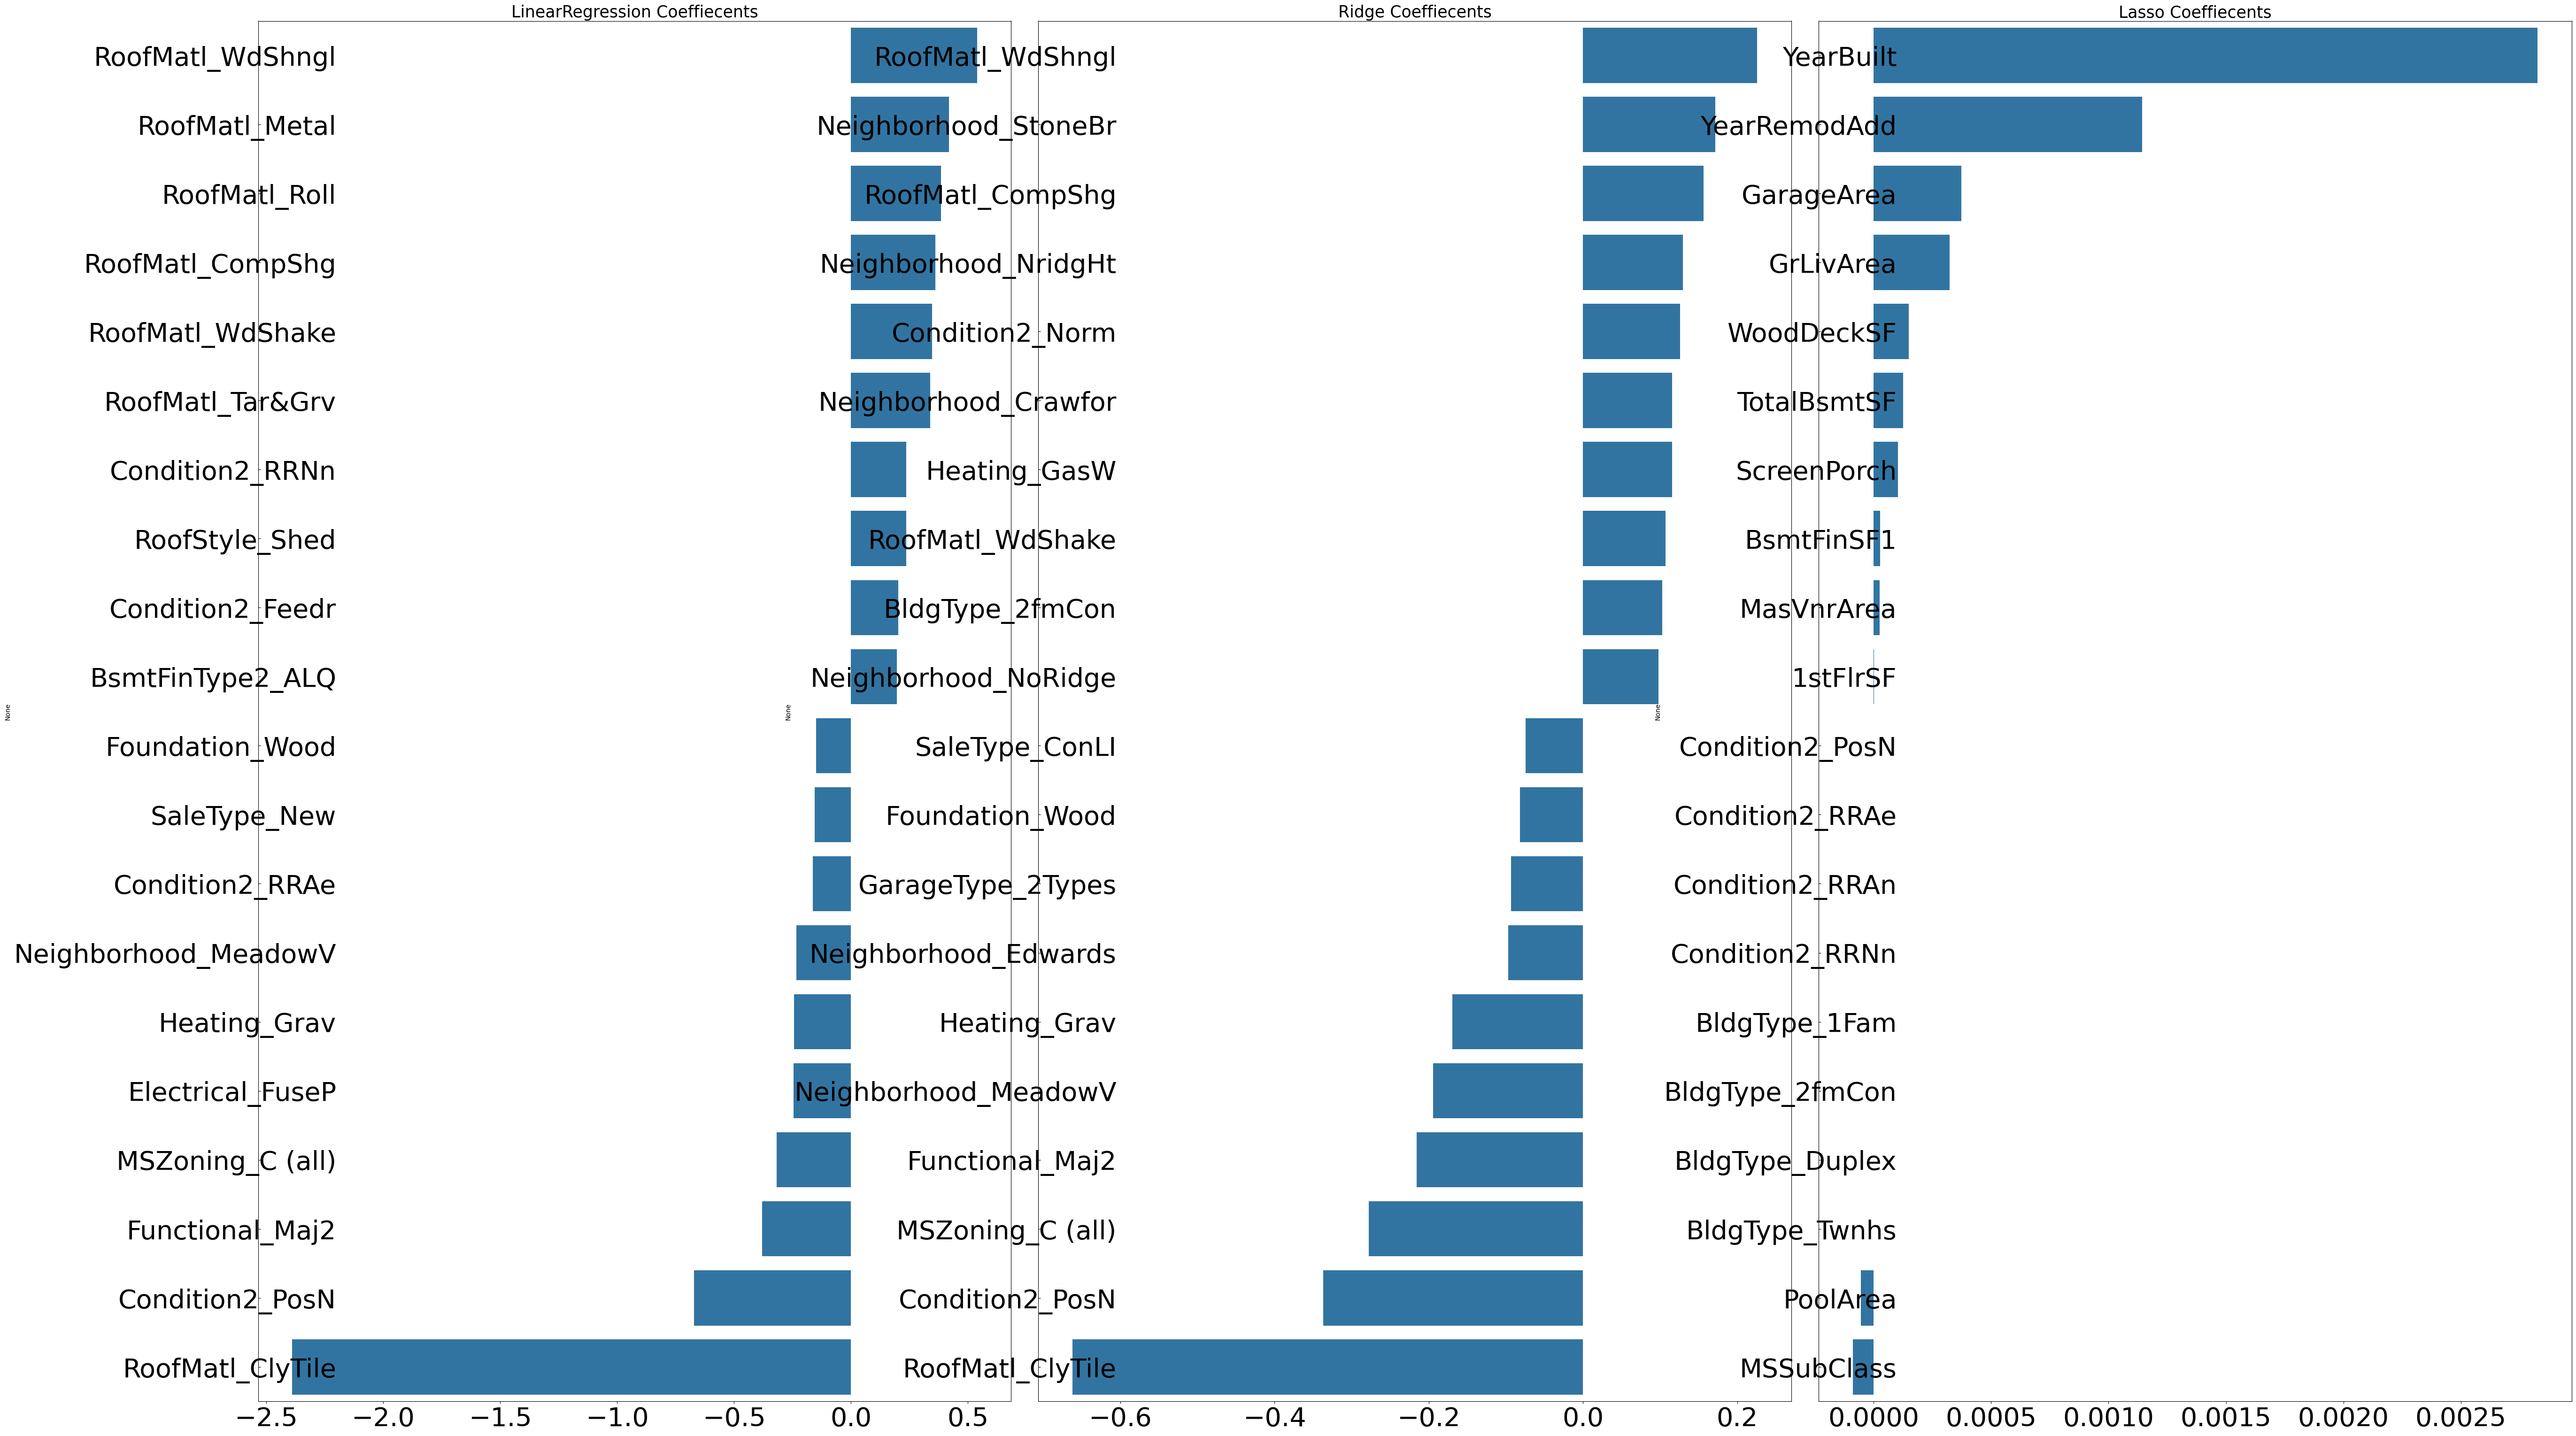

In [12]:
def visualize_coef(models):
    fig, axs = plt.subplots(figsize = (50, 30), nrows = 1, ncols = 3)
    fig.tight_layout()
    for i_num, model in enumerate(models):
        coef_high, coef_low = get_top_bottom_coef(model)
        coef_concat = pd.concat([coef_high, coef_low])
        axs[i_num].set_title(model.__class__.__name__+' Coeffiecents',
                             size = 25)
        axs[i_num].tick_params(axis = 'y', direction = 'in', pad = -120)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(40)
        sns.barplot(x = coef_concat.values, y = coef_concat.index,
                    ax = axs[i_num])

model = [lr_reg, ridge_reg, lasso_reg]
visualize_coef(models)

In [13]:
from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):
    for model in models:
        rmse_list = np.sqrt(-cross_val_score(model, X_features, y_target,
                            scoring = "neg_mean_squared_error", cv = 5))
        rmse_avg = np.mean(rmse_list)
        print(model.__class__.__name__, np.round(rmse_list, 3))
        print(model.__class__.__name__, np.round(rmse_avg, 3))

models = [lr_reg, ridge_reg, lasso_reg]
get_avg_rmse_cv(models)

LinearRegression [0.135 0.165 0.168 0.111 0.198]
LinearRegression 0.155
Ridge [0.117 0.154 0.142 0.117 0.189]
Ridge 0.144
Lasso [0.161 0.204 0.177 0.181 0.265]
Lasso 0.198


In [14]:
from sklearn.model_selection import GridSearchCV

def print_best_params(model, params):
    grid_model = GridSearchCV(model, param_grid = params,
                    scoring = "neg_mean_squared_error", cv = 5)
    grid_model.fit(X_features, y_target)
    rmse = np.sqrt(-1 * grid_model.best_score_)
    print(model.__class__.__name__, np.round(rmse, 4),
          grid_model.best_params_)
    return grid_model.best_estimator_

ridge_params = {"alpha": [0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {"alpha": [0.001, 0.005, 0.008, 0.03, 0.05, 0.1, 0.5, 1, 5, 10]}

best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 0.1418 {'alpha': 12}
Lasso 0.142 {'alpha': 0.001}


LinearRegression 0.129
Ridge 0.121
Lasso 0.117


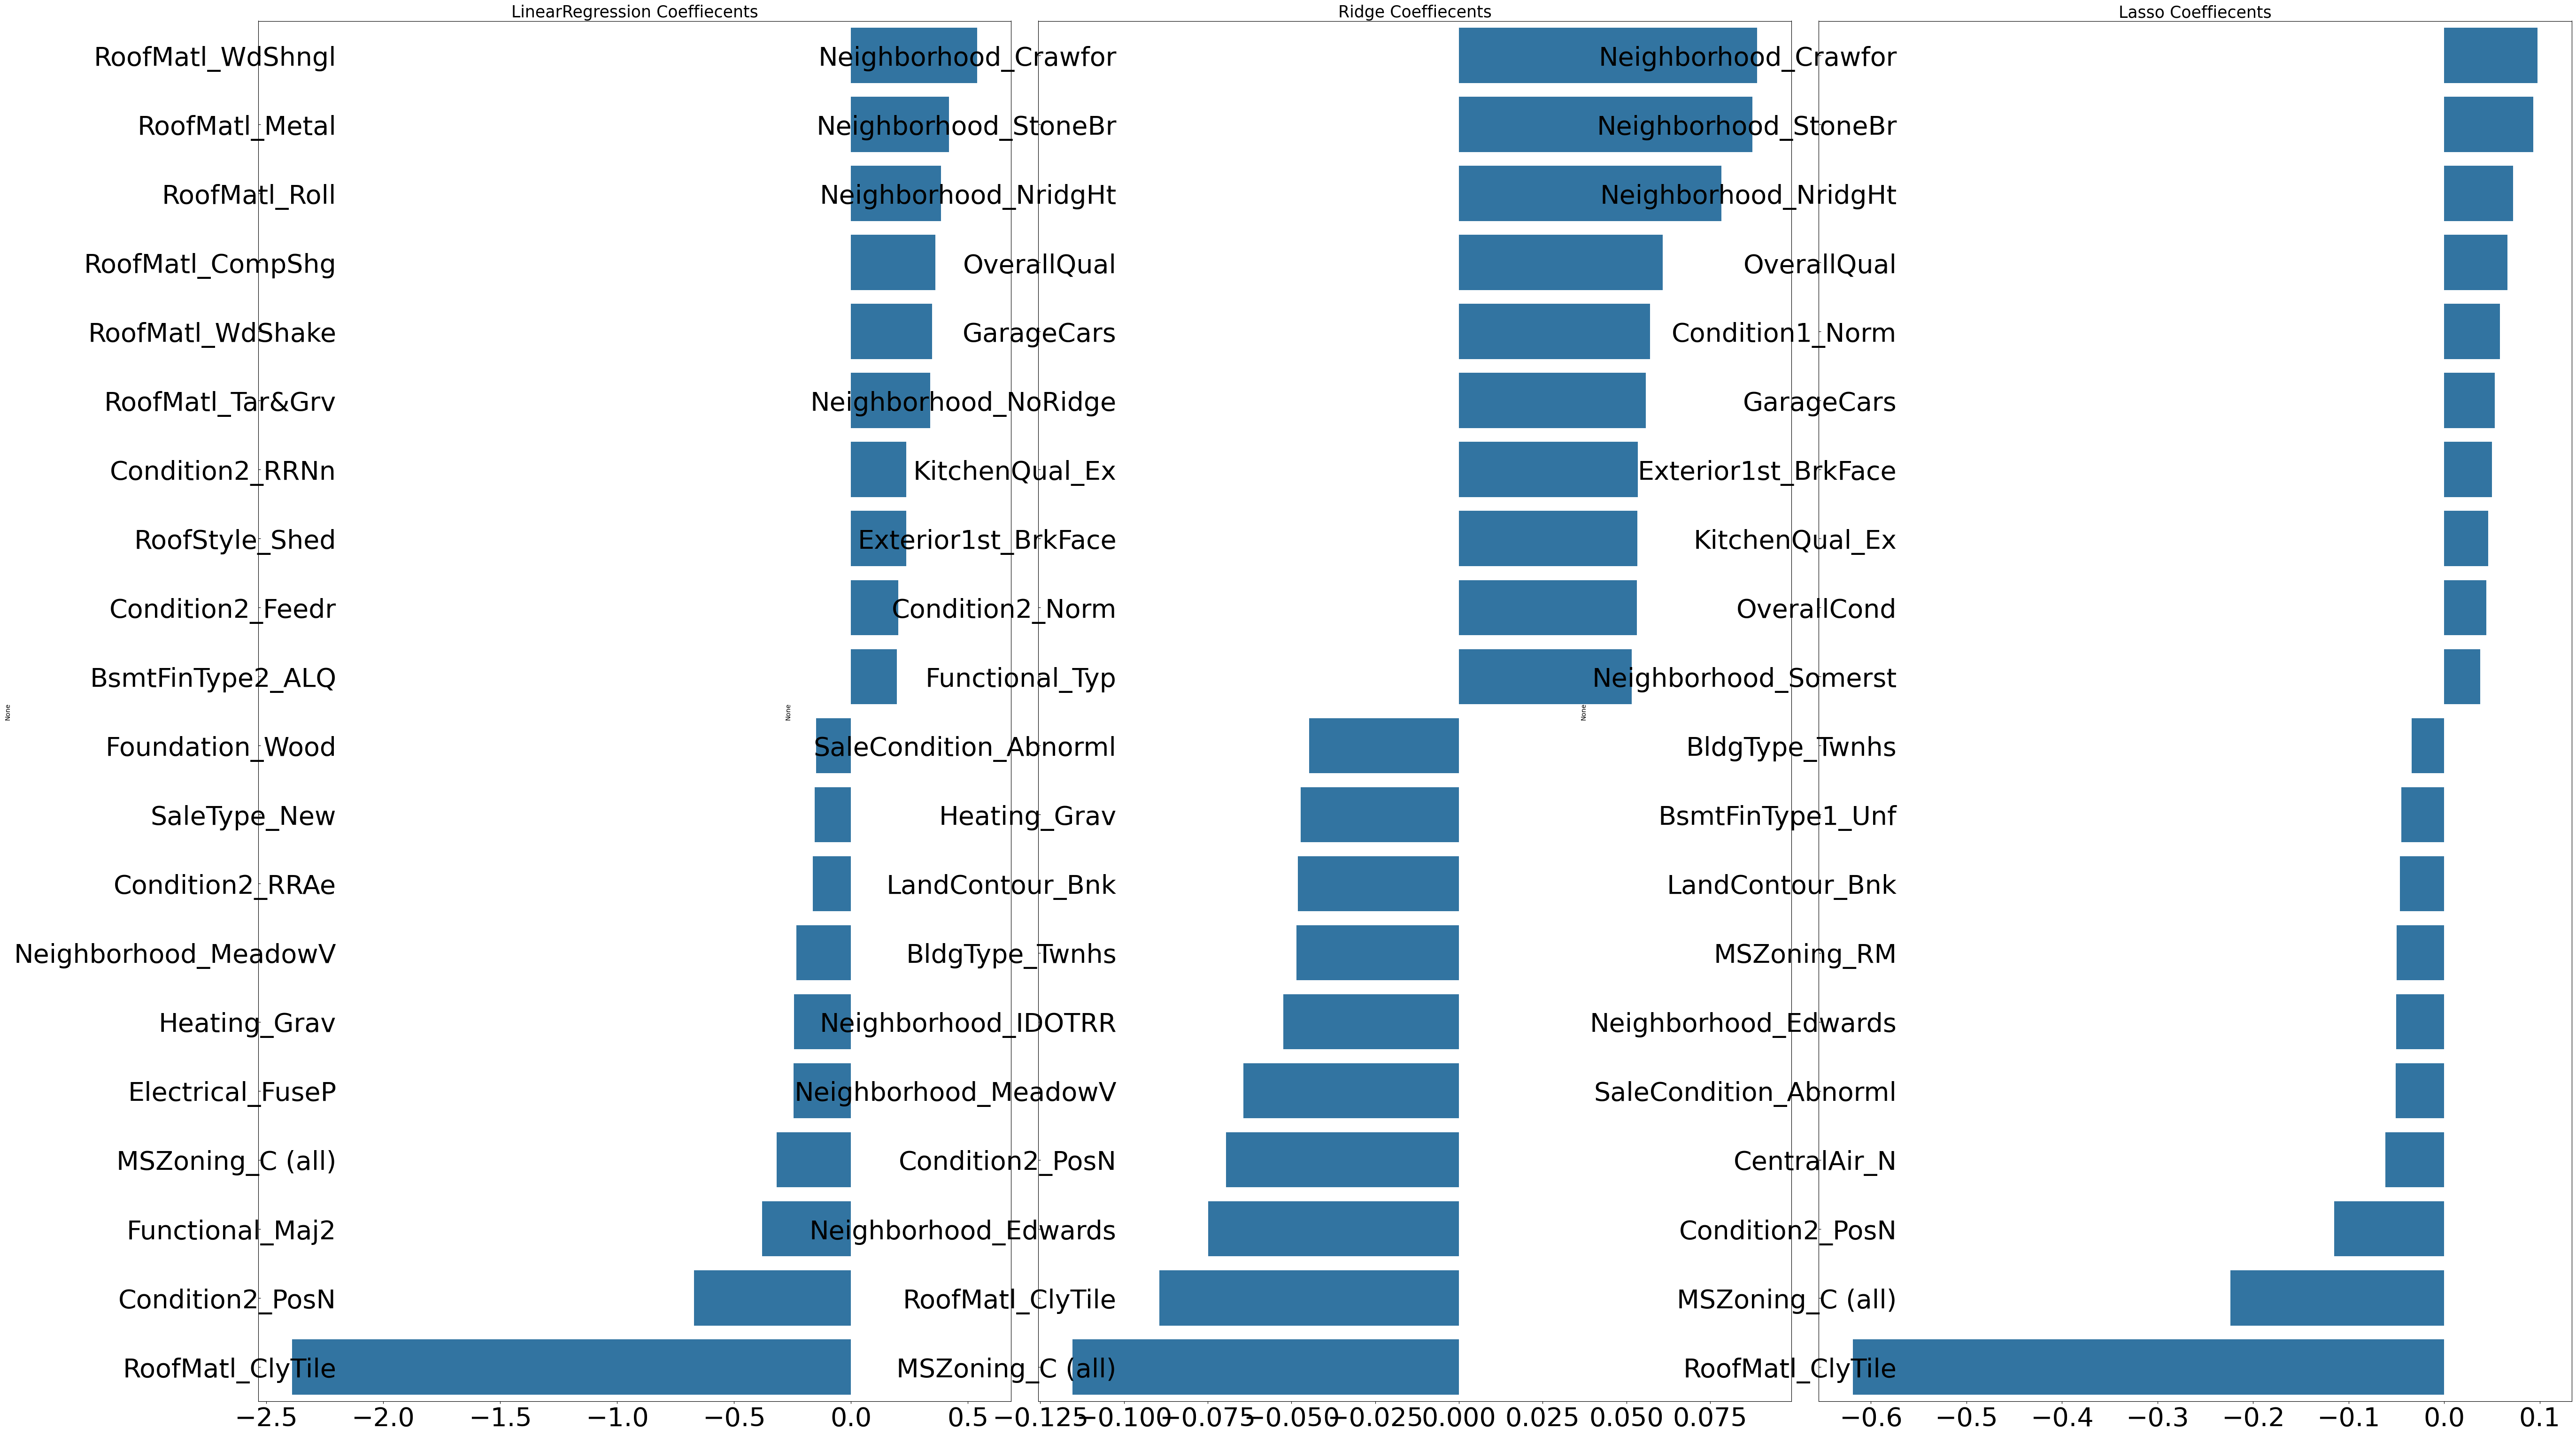

In [15]:
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha = 12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

visualize_coef(models)

In [16]:
from scipy.stats import skew

features_index = df.dtypes[df.dtypes != "object"].index
skew_features = df[features_index].apply(lambda x: skew(x))
skew_features_top = skew_features[skew_features > 1]
print(skew_features_top.sort_values(ascending = False))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


In [17]:
df[skew_features_top.index] = np.log1p(df[skew_features_top.index])

In [18]:
df_ohe = pd.get_dummies(df)
y_target = df_ohe["SalePrice"]
X_features = df_ohe.drop("SalePrice", axis = 1, inplace = False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target,
                test_size = 0.2, random_state = 156)

ridge_params = {"alpha": [0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {"alpha": [0.001, 0.005, 0.008, 0.03, 0.05, 0.1, 0.5, 1, 5, 10]}

best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 0.1275 {'alpha': 10}
Lasso 0.1252 {'alpha': 0.001}


LinearRegression 0.128
Ridge 0.122
Lasso 0.119


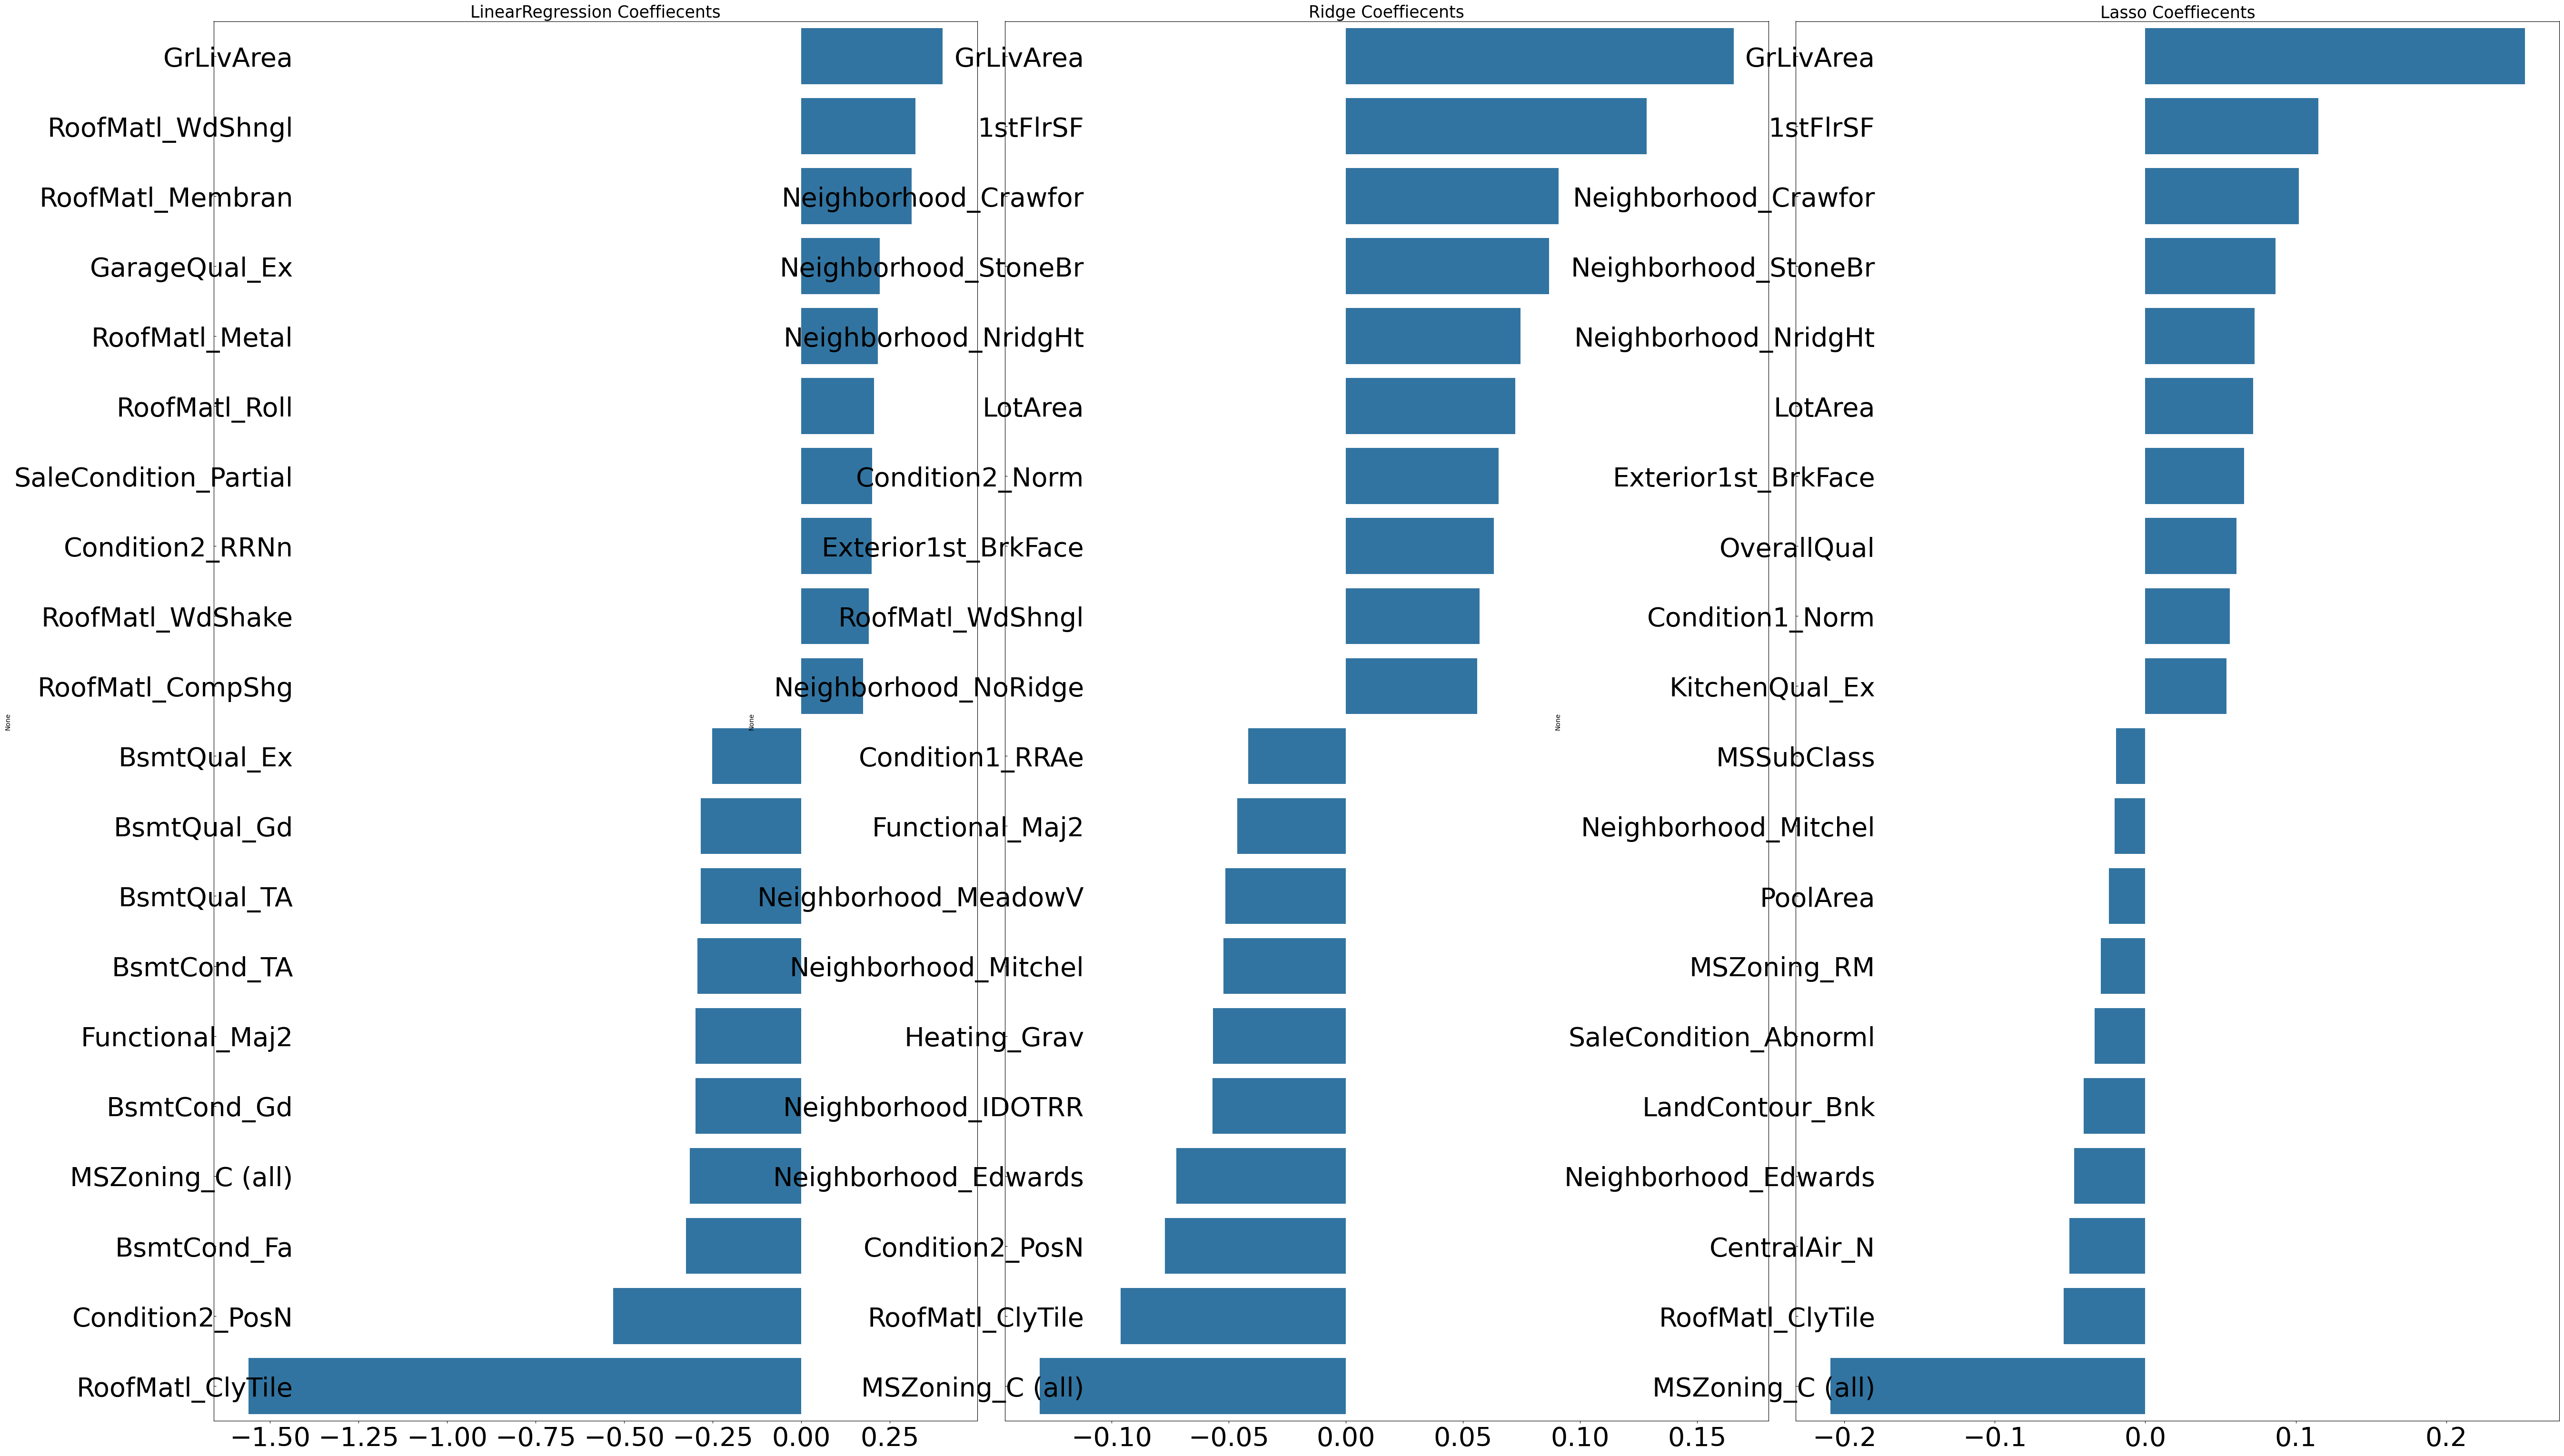

In [19]:
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha = 10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

visualize_coef(models)

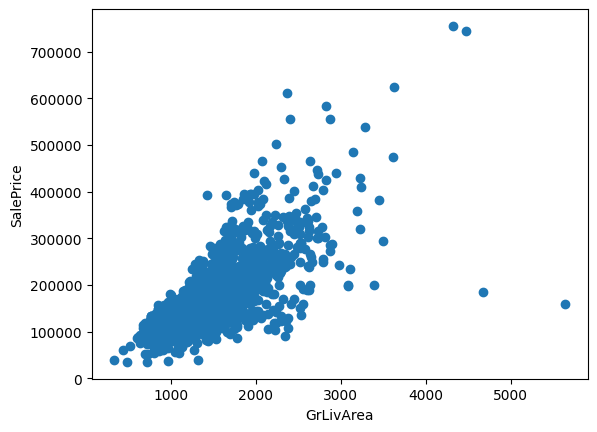

In [20]:
plt.scatter(x = df_org["GrLivArea"], y = df_org["SalePrice"])
plt.ylabel("SalePrice")
plt.xlabel("GrLivArea")
plt.show()

In [22]:
cond1 = df_ohe["GrLivArea"] > np.log1p(4000)
cond2 = df_ohe["SalePrice"] < np.log1p(500000)
outlier_index = df_ohe[cond1 & cond2].index

print(outlier_index.values)
print(df_ohe.shape)
df_ohe.drop(outlier_index, axis = 0, inplace = True)
print(df_ohe.shape)

[ 523 1298]
(1460, 271)
(1458, 271)


In [23]:
y_target = df_ohe["SalePrice"]
X_features = df_ohe.drop("SalePrice", axis = 1, inplace = False)

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target,
                test_size = 0.2, random_state = 156)

ridge_params = {"alpha": [0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {"alpha": [0.001, 0.005, 0.008, 0.03, 0.05, 0.1, 0.5, 1, 5, 10]}

best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 0.1125 {'alpha': 8}
Lasso 0.1122 {'alpha': 0.001}


LinearRegression 0.129
Ridge 0.103
Lasso 0.1


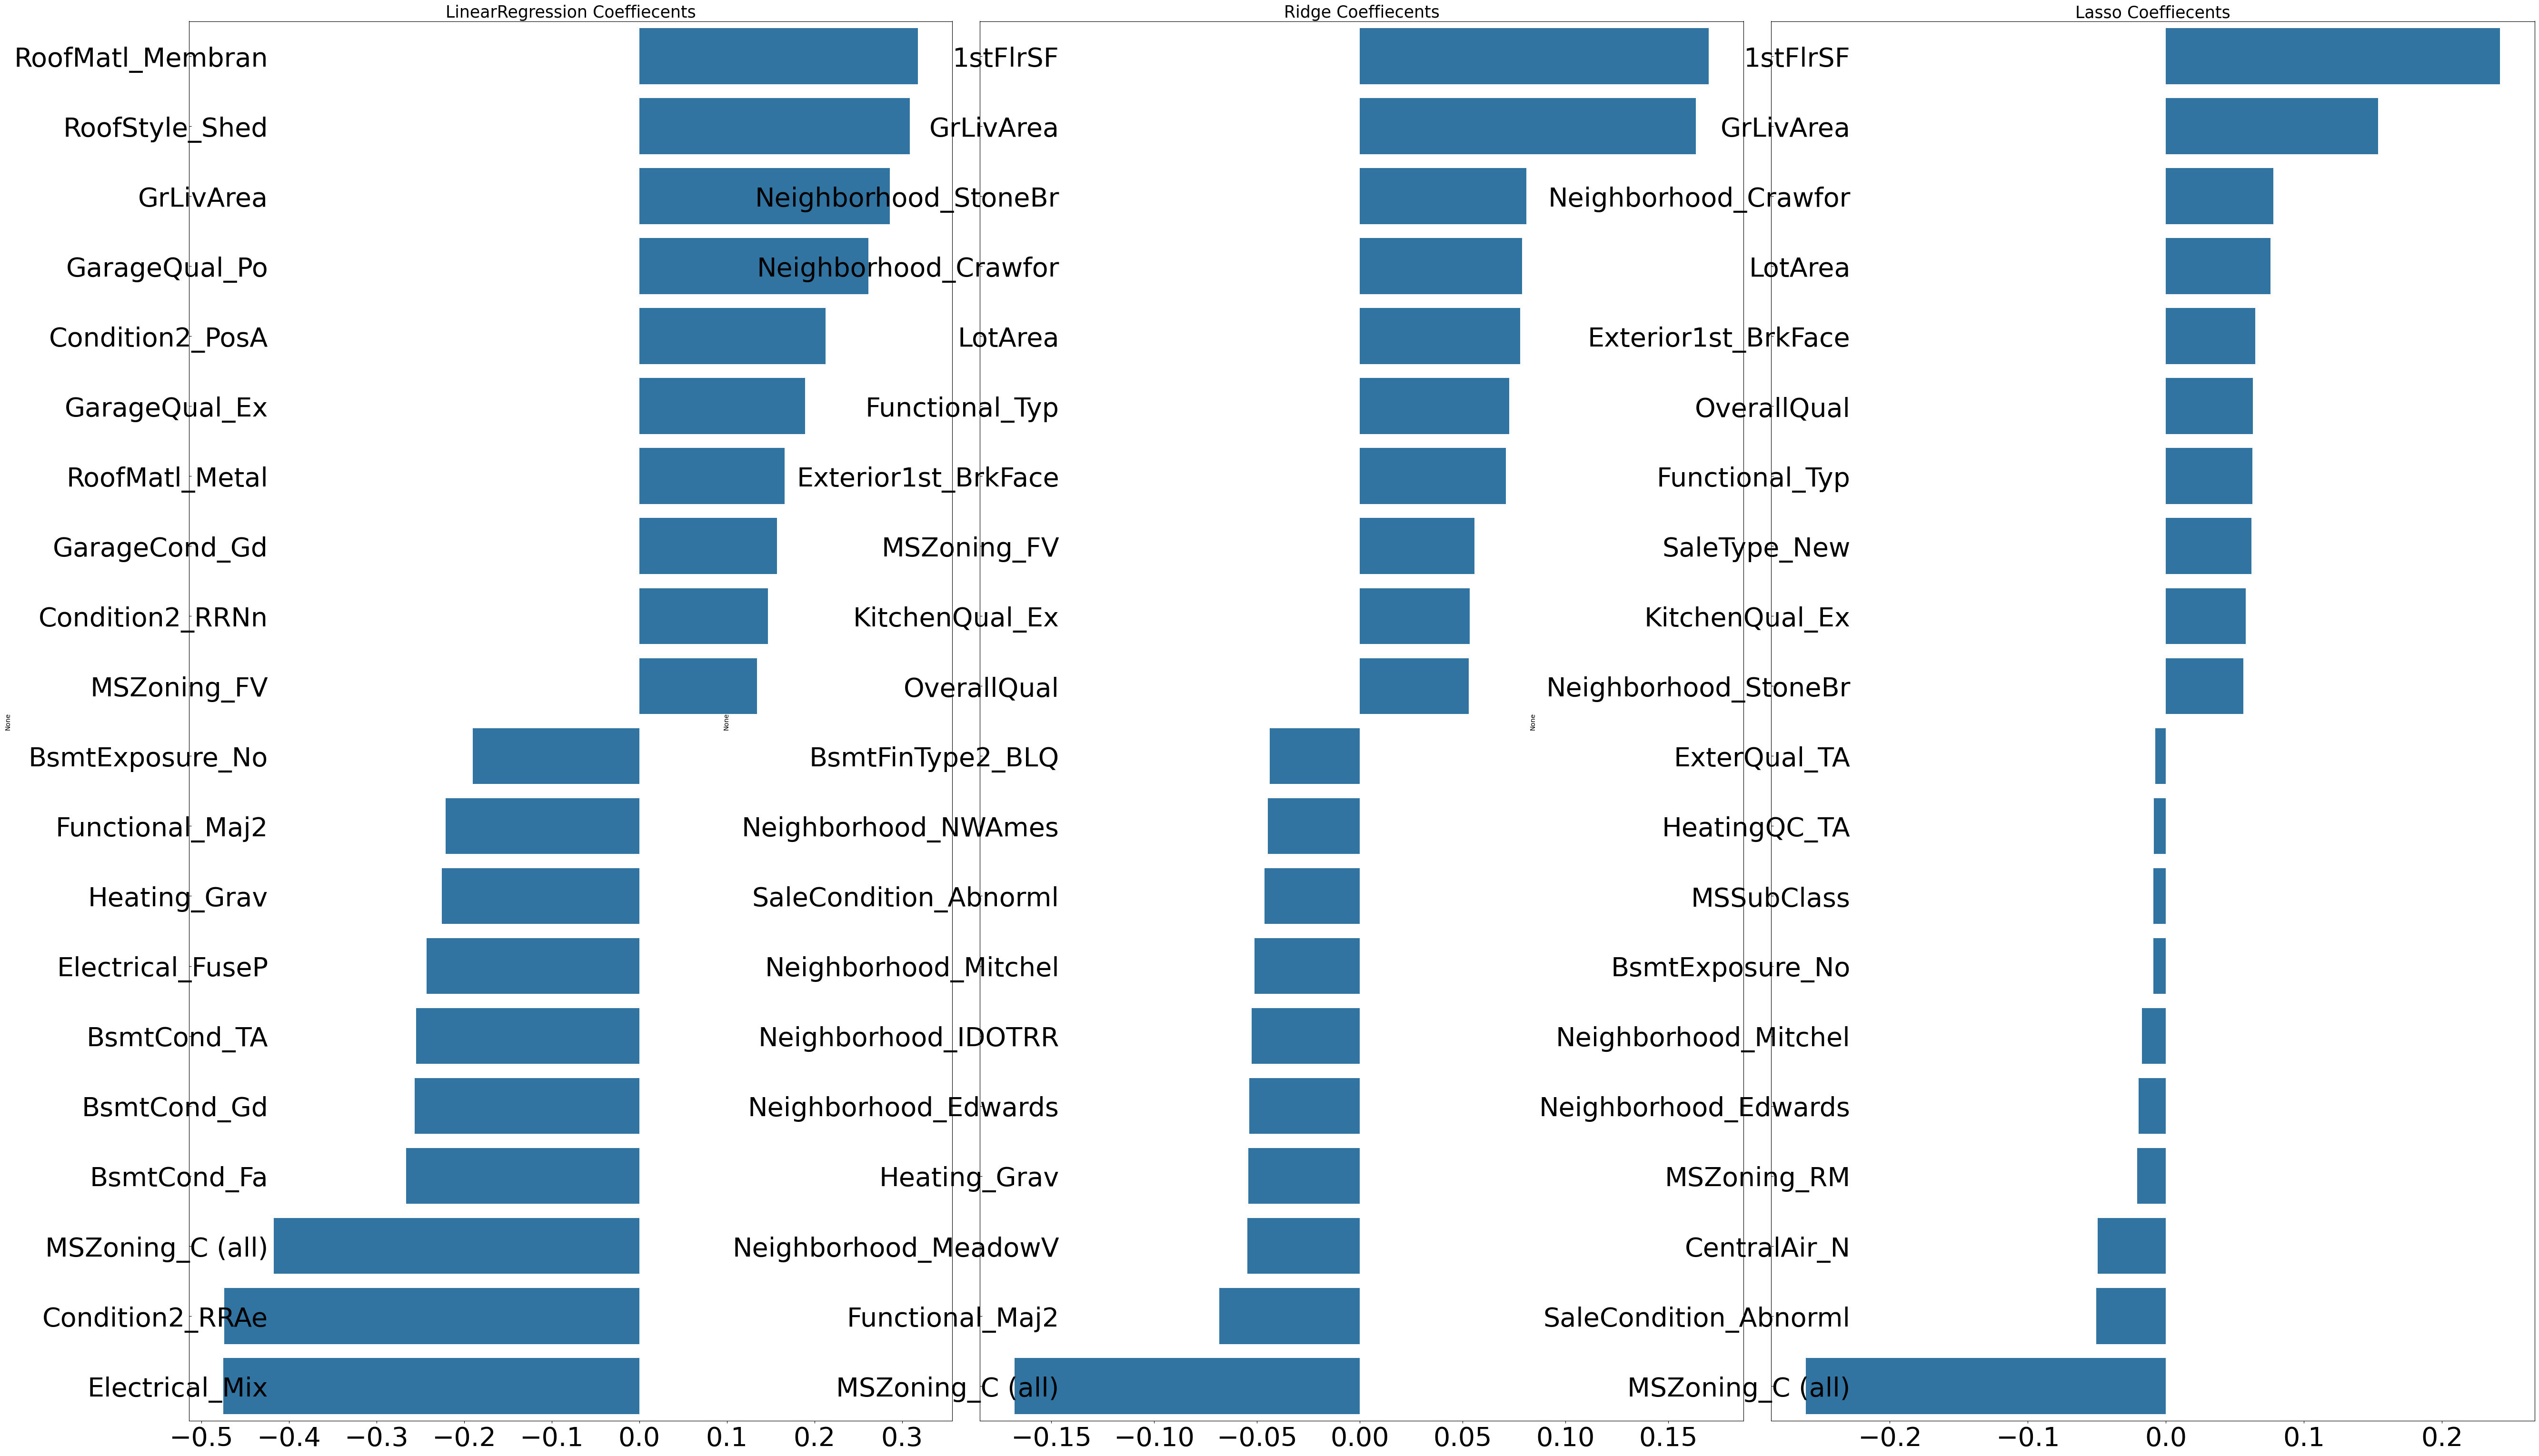

In [24]:
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha = 8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

visualize_coef(models)

In [25]:
from xgboost import XGBRegressor

xgb_params = {"n_estimators": [1000]}
xgb_reg = XGBRegressor(n_estimators = 1000, learning_rate = 0.05,
                    colsample_bytree = 0.5, subsample = 0.8)
best_xgb = print_best_params(xgb_reg, xgb_params)

XGBRegressor 0.1198 {'n_estimators': 1000}


In [26]:
from lightgbm import LGBMRegressor

lgbm_params = {"n_estimators": [1000]}
lgbm_reg = LGBMRegressor(n_estimators = 1000, learning_rate = 0.05,
                    num_leaves = 4, subsample = 0.6, colsample_bytree = 0.4,
                    reg_lambda = 10, n_jobs = -1, verbose = -1)
best_lgbm = print_best_params(lgbm_reg, lgbm_params)

LGBMRegressor 0.1163 {'n_estimators': 1000}


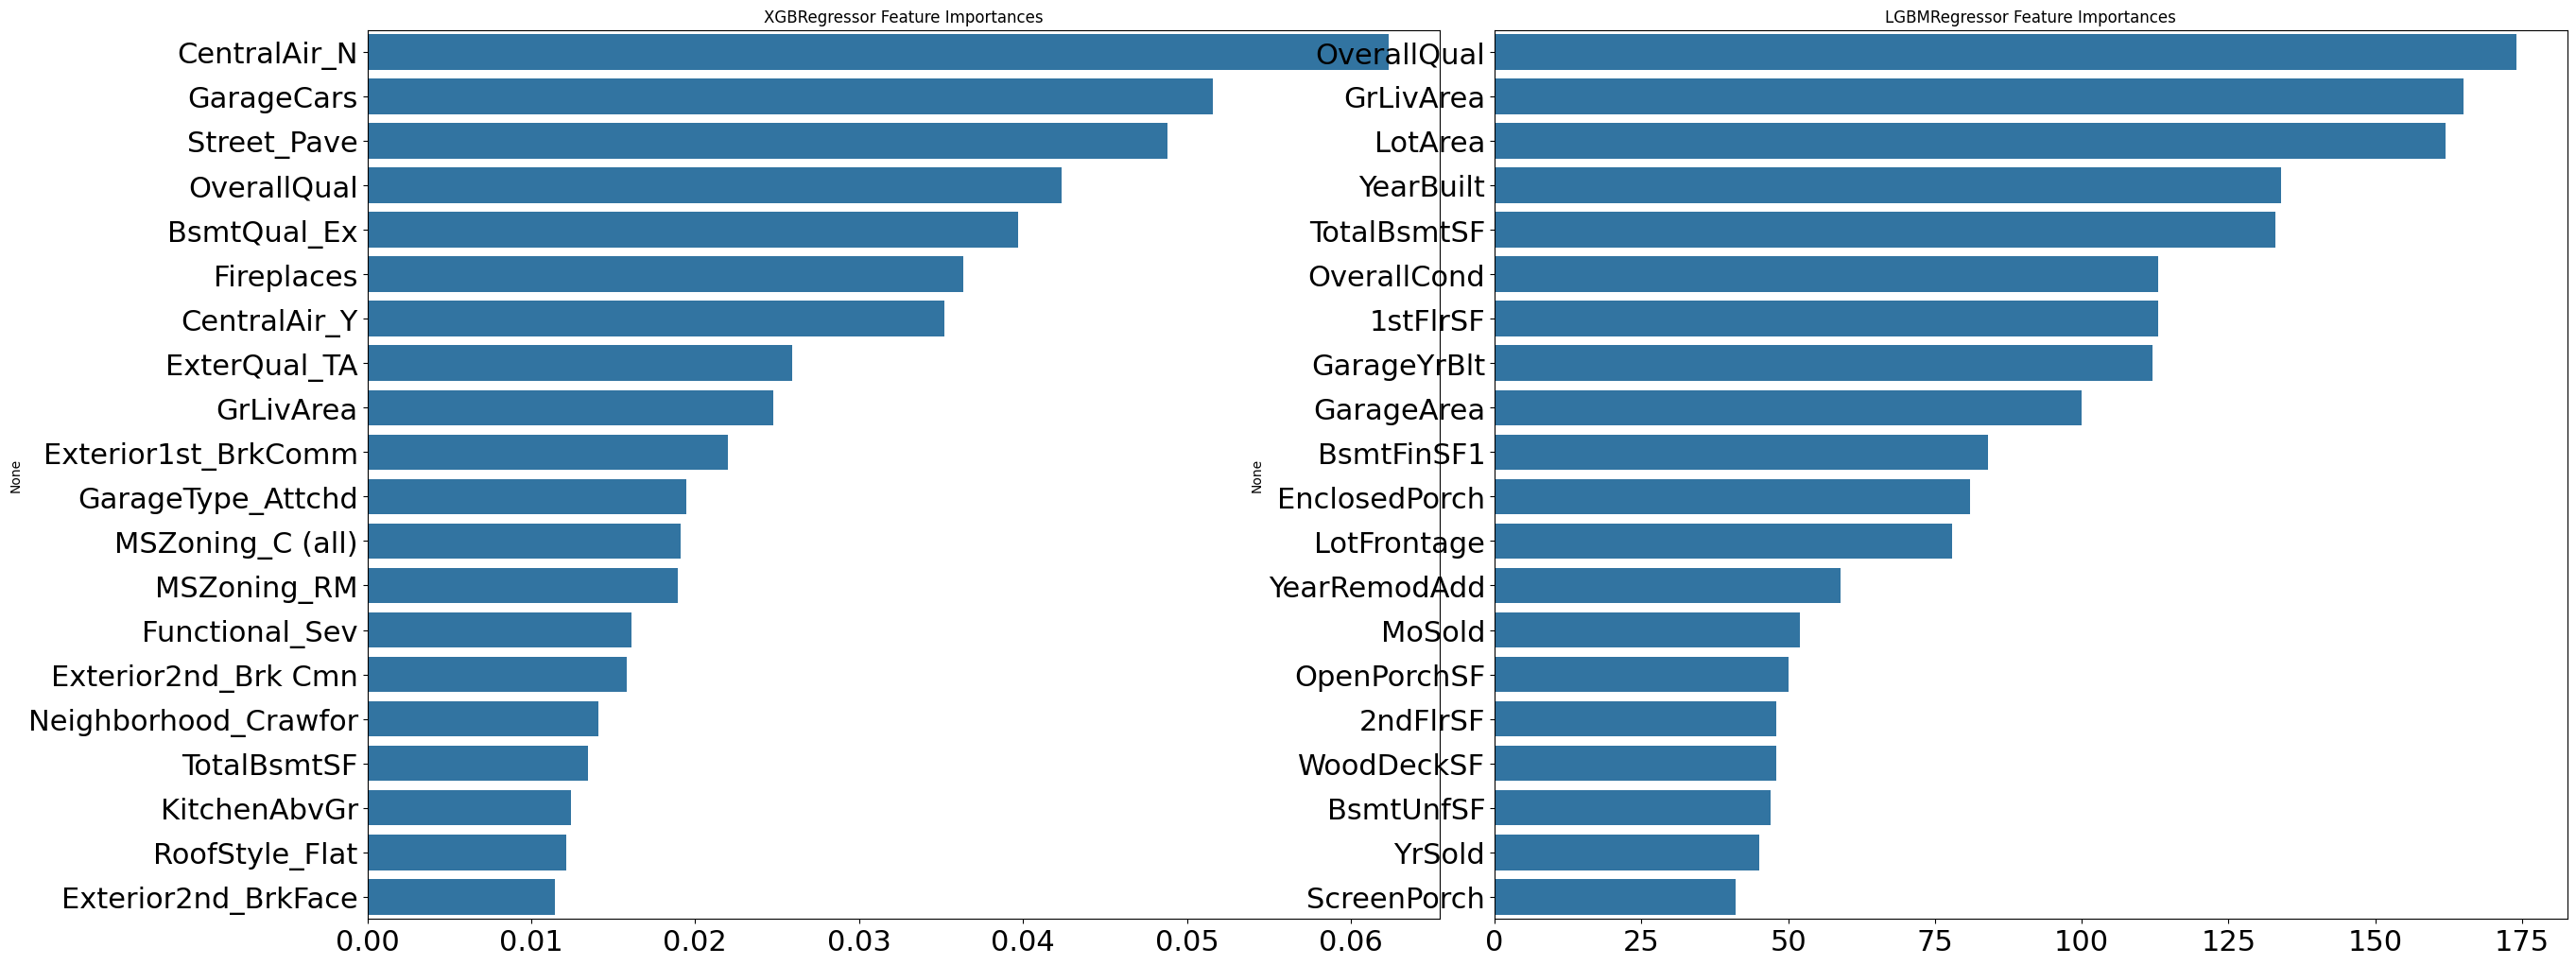

In [27]:
def get_top_features(model):
    ftr_importances_values = model.feature_importances_
    ftr_importances = pd.Series(ftr_importances_values,
                                index = X_features.columns)
    ftr_top20 = ftr_importances.sort_values(ascending = False)[:20]
    return ftr_top20

def visualize_ftr_importances(models):
    fig, axs = plt.subplots(figsize = (24, 10), nrows = 1, ncols = 2)
    fig.tight_layout()
    for i_num, model in enumerate(models):
        ftr_top20 = get_top_features(model)
        axs[i_num].set_title(model.__class__.__name__+" Feature Importances")
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x = ftr_top20.values, y = ftr_top20.index, ax = axs[i_num])

models = [best_xgb, best_lgbm]
visualize_ftr_importances(models)

In [28]:
def get_rmse_pred(preds):
    for key in preds.keys():
        pred_value = preds[key]
        mse = mean_squared_error(y_test, pred_value)
        rmse = np.sqrt(mse)
        print(key, rmse)

ridge_reg = Ridge(alpha = 8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha = 0.001)
lasso_reg.fit(X_train, y_train)

ridge_pred = ridge_reg.predict(X_test)
lasso_pred = lasso_reg.predict(X_test)

pred = 0.4 * ridge_pred + 0.6 * lasso_pred
print(pred[:20])
preds = {"최종혼합": pred, "Ridge": ridge_pred, "Lasso": lasso_pred}
get_rmse_pred(preds)

[11.65291734 12.23530591 11.99009222 11.43330322 12.10320739 12.14435569
 12.34866226 13.2355212  11.92186082 12.04078814 12.332935   11.66458034
 12.46435282 12.39388492 12.12612379 12.55614651 12.21924031 11.85500129
 12.06554116 12.29554289]
최종혼합 0.10007930884470521
Ridge 0.10345177546603253
Lasso 0.10024170460890057


In [30]:
xgb_reg = XGBRegressor(n_estimators = 1000, learning_rate = 0.05,
            colsample_bytree = 0.5, subsample = 0.8)
lgbm_reg = LGBMRegressor(n_estimators = 1000, learning_rate = 0.05,
                         num_leaves = 4, subsample = 0.6, colsample_bytree = 0.4,
                         reg_lambda = 10, n_jobs = -1, verbose = -1)
xgb_reg.fit(X_train, y_train)
lgbm_reg.fit(X_train, y_train)
xgb_pred = xgb_reg.predict(X_test)
lgbm_pred = lgbm_reg.predict(X_test)

pred = 0.5 * xgb_pred + 0.5 * lgbm_pred
print(pred[:20])
preds = {"최종혼합": pred, "XGB": xgb_pred, "LGBM": lasso_pred}

get_rmse_pred(preds)

[11.66712443 12.21476411 11.96648419 11.43731404 12.0964782  12.09661876
 12.36651116 13.11404671 11.94829786 11.98867693 12.25726224 11.69585006
 12.50967206 12.37308554 12.16315358 12.60969103 12.17327266 11.94221113
 11.98767886 12.27072833]
최종혼합 0.10277689340617208
XGB 0.10946473825650248
LGBM 0.10024170460890057


In [37]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):
    kf = KFold(n_splits = n_folds, shuffle = False)
    train_fold_pred = np.zeros((X_train_n.shape[0], 1))
    test_pred = np.zeros((X_test_n.shape[0], n_folds))
    print(model.__class__.__name__, "model시작")

    for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n)):
        print("폴더세트 :", folder_counter, "시작")
        X_tr = X_train_n[train_index]
        y_tr = y_train_n[train_index]
        X_te = X_train_n[valid_index]
        y_te = y_train_n[valid_index]
        model.fit(X_tr, y_tr)
        train_fold_pred[valid_index, :] = model.predict(X_te).reshape(-1, 1)
        test_pred[:, folder_counter] = model.predict(X_test_n)

    test_pred_mean = np.mean(test_pred, axis = 1).reshape(-1, 1)
    return train_fold_pred, test_pred_mean

In [38]:
X_train_n = X_train.values
X_test_n = X_test.values
y_train_n = y_train.values

ridge_train, ridge_test = get_stacking_base_datasets(ridge_reg, X_train_n,
                            y_train_n, X_test_n, 5)
lasso_train, lasso_test = get_stacking_base_datasets(lasso_reg, X_train_n,
                            y_train_n, X_test_n, 5)
xgb_train, xgb_test = get_stacking_base_datasets(xgb_reg, X_train_n,
                            y_train_n, X_test_n, 5)
lgbm_train, lgbm_test = get_stacking_base_datasets(lgbm_reg, X_train_n,
                            y_train_n, X_test_n, 5)

Ridge model시작
폴더세트 : 0 시작
폴더세트 : 1 시작
폴더세트 : 2 시작
폴더세트 : 3 시작
폴더세트 : 4 시작
Lasso model시작
폴더세트 : 0 시작
폴더세트 : 1 시작
폴더세트 : 2 시작
폴더세트 : 3 시작
폴더세트 : 4 시작
XGBRegressor model시작
폴더세트 : 0 시작
폴더세트 : 1 시작
폴더세트 : 2 시작
폴더세트 : 3 시작
폴더세트 : 4 시작
LGBMRegressor model시작
폴더세트 : 0 시작
폴더세트 : 1 시작
폴더세트 : 2 시작
폴더세트 : 3 시작
폴더세트 : 4 시작


In [40]:
Stack_final_X_train = np.concatenate((ridge_train, lasso_train,
                                      xgb_train, lgbm_train), axis = 1)
Stack_final_X_test = np.concatenate((ridge_test, lasso_test,
                                      xgb_test, lgbm_test), axis = 1)

meta_model_lasso = Lasso(alpha = 0.0005)

meta_model_lasso.fit(Stack_final_X_train, y_train)
final = meta_model_lasso.predict(Stack_final_X_test)
mse = mean_squared_error(y_test, final)
rmse = np.sqrt(mse)
print("스태킹 최종 RMSE: ", rmse)

스태킹 최종 RMSE:  0.09788179395905446
